# RetailIQ
## E-Commerce Business Intelligence & Customer Analytics

### Project Overview
RetailIQ is a data analytics project focused on understanding e-commerce sales performance, product trends, customer purchasing behaviour, and business insights using Python and Pandas.

### Objective
To transform raw retail transaction data into meaningful business insights through data exploration, cleaning, manipulation, and analysis.

### Dataset
UCI Online Retail Dataset

### Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Author
ASWIN KUMAR V.

In [163]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("All libraries are working!")

All libraries are working!


In [113]:
#loading the dataset

df=pd.read_excel("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\04_Pandas\\RetailIQ\\data\\online_retail.xlsx")

print("Dataset loaded successfully")

Dataset loaded successfully


In [114]:
display(df.head())
display(df.tail())
print("\nColumns: ")
display(df.columns.tolist())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France



Columns: 


['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [115]:
df.info()
display(df.describe().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60


In [116]:
print("Number of Transactions and Columns : ",df.shape)
print("\nNumber of unique customers : ",df['CustomerID'].nunique())
print("\nNumber of unique countries : ",df['Country'].nunique())
print(f"\nColumn containing missing values :\n{df.isnull().sum()}")
print("\nDuplicated rows : ",df.duplicated().sum())

Number of Transactions and Columns :  (541909, 8)

Number of unique customers :  4372

Number of unique countries :  38

Column containing missing values :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicated rows :  5268


In [117]:
print(df.dtypes)
print('Invoice types :')
print(df['InvoiceNo'].astype(str).str.startswith('C').sum())
print('Unique products')
print(df['StockCode'].nunique())

#Quantity statistics
display(df['Quantity'].describe())
#Price statistics
display(df['UnitPrice'].describe())
#Country-wise transacation count
display(df['Country'].value_counts().head(10))

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object
Invoice types :
9288
Unique products
4070


count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

In [118]:
print("Negative quantities : ",(df['Quantity']<0).sum())
print("Zero quantities     : ",(df['Quantity']==0).sum())
print("Negative Prices     : ",(df['UnitPrice']<0).sum())
print("Zero Prices         : ",(df['UnitPrice']<0).sum())
print("Missing description : ",df['Description'].isna().sum())
print("Missing Customer IDs: ",df['CustomerID'].isnull().sum())

Negative quantities :  10624
Zero quantities     :  0
Negative Prices     :  2
Zero Prices         :  2
Missing description :  1454
Missing Customer IDs:  135080


In [119]:
cancelled = df[
    df['InvoiceNo'].astype(str).str.startswith('C')
    ]
display(cancelled.head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [120]:
retail=df.copy()
display(len(df))
display(len(retail))
display(
    retail[retail['Description'].isnull()].head(10)
)
display(
    retail[retail['UnitPrice']<0]
)

541909

541909

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [121]:
print("Missing description AND zero price: ",
     (retail['Description'].isnull() & (retail['UnitPrice']==0)).sum())
print("Missing description AND missing customer: ",
     (retail['Description'].isnull() & retail['CustomerID'].isnull()).sum())
print("Negative prices: ",
      (retail['UnitPrice']<0).sum())
print("Zero prices: ",
      (retail['UnitPrice']==0).sum() )
print('Missing descriptions: ',
      retail['Description'].isnull().sum())

Missing description AND zero price:  1454
Missing description AND missing customer:  1454
Negative prices:  2
Zero prices:  2515
Missing descriptions:  1454


In [122]:
retail_clean=retail.drop_duplicates().copy()
print("Rows Before: ",len(retail))
print("Rows After : ",len(retail_clean))
print("Duplicates remaining : ",retail_clean.duplicated().sum())

Rows Before:  541909
Rows After :  536641
Duplicates remaining :  0


In [123]:
retail_clean=retail_clean.dropna(subset=['Description']).copy()
print("Rows after removing missing descriptions: ",len(retail_clean))
print("Missing descriptions remaining: ",
      retail_clean['Description'].isnull().sum())

Rows after removing missing descriptions:  535187
Missing descriptions remaining:  0


In [124]:
print("Zero Prices         : ",(df['UnitPrice']==0).sum())
print("Negative Prices     : ",(df['UnitPrice']<0).sum())

Zero Prices         :  2515
Negative Prices     :  2


In [125]:
cancelled=retail_clean[
    retail_clean['InvoiceNo'].astype(str).str.startswith("C")
]
print("Cancelled transaction rows : ",len(cancelled))
print("Unique cancelled invoices  : ",cancelled['InvoiceNo'].nunique())

Cancelled transaction rows :  9251
Unique cancelled invoices  :  3836


In [126]:
returns=retail_clean[retail_clean['Quantity']<0]
print("Return transaction rows: ",len(returns))
print("Unique return invoices: ",returns['InvoiceNo'].nunique())

Return transaction rows:  9725
Unique return invoices:  4310


In [127]:
print("Negative quantity in cancelled transactions : ",(cancelled['Quantity']<0).sum())
print("Negative quantity outside cancelled transactions : ",((retail_clean['Quantity']<0)&(-retail_clean['InvoiceNo'].astype(str).str.startswith("C"))).sum())


Negative quantity in cancelled transactions :  9251
Negative quantity outside cancelled transactions :  474


In [128]:
retail_clean["Revenue"]=(
    retail_clean['Quantity']*retail_clean['UnitPrice']
)
display(retail_clean.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [129]:
conditions=[
    retail_clean['InvoiceNo'].astype(str).str.startswith('C'),
    retail_clean['Quantity']<0,
    retail_clean['UnitPrice']<0,
    retail_clean['Quantity']>0
]
choices=[
    'Cancellation',
    'Return',
    'Adjustment',
    'Sale'
]
retail_clean['TransactionType']=np.select(
    conditions,
    choices,
    default='Others'
)
print(retail_clean['TransactionType'].value_counts())

TransactionType
Sale            525460
Cancellation      9251
Return             474
Adjustment           2
Name: count, dtype: int64


In [130]:
display(
    retail_clean.groupby("TransactionType")['Revenue'].agg(['count','sum','mean'])
)

,count,sum,mean
TransactionType,,,
Adjustment,2,-2.212412e+04,-11062.060000
Cancellation,9251,-8.939797e+05,-96.636010
Return,474,0.000000e+00,0.000000
Sale,525460,1.064211e+07,20.252942


In [131]:
return_analysis=retail_clean[
    retail_clean['TransactionType']=='Return'
]
print('Return quantity sum: ',return_analysis['Quantity'].sum())
print("Return unit price sum : ",return_analysis['Revenue'].sum())
display(return_analysis[['InvoiceNo','StockCode','Quantity','UnitPrice','Revenue']].head(15))

Return quantity sum:  -160801
Return unit price sum :  0.0


,InvoiceNo,StockCode,Quantity,UnitPrice,Revenue
7313,537032,21275,-30,0.0,-0.0
13217,537425,84968F,-20,0.0,-0.0
13218,537426,84968E,-35,0.0,-0.0
13264,537432,35833G,-43,0.0,-0.0
21338,538072,22423,-13,0.0,-0.0
21518,538090,20956,-723,0.0,-0.0
22296,538161,46000S,-100,0.0,-0.0
22297,538162,46000M,-100,0.0,-0.0
42564,540010,22501,-100,0.0,-0.0
42566,540012,22502,-100,0.0,-0.0


In [132]:
sales=retail_clean[
    retail_clean['TransactionType']=='Sale'
].copy()
print("Sales rows : ",len(sales))

country_revenue=(
    sales.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
)
display(country_revenue.head(10))

Sales rows :  525460


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [133]:
print(retail_clean.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False))

Country
United Kingdom          22040
Germany                   603
France                    461
EIRE                      360
Belgium                   119
Spain                     105
Netherlands               101
Switzerland                74
Portugal                   71
Australia                  69
Italy                      55
Finland                    48
Sweden                     46
Norway                     40
Channel Islands            33
Japan                      28
Poland                     24
Denmark                    21
Cyprus                     20
Austria                    19
Hong Kong                  15
Unspecified                13
Malta                      10
Singapore                  10
Israel                      9
Iceland                     7
USA                         7
Greece                      6
Canada                      6
Czech Republic              5
European Community          5
Bahrain                     4
Lithuania                   4
Un

In [134]:
print(retail_clean.groupby('StockCode')['Revenue'].sum().sort_values(ascending=False).head(10))

StockCode
DOT       206245.48
22423     164459.49
47566      98243.88
85123A     97838.45
85099B     92175.79
23084      66661.63
POST       66230.64
22086      63715.24
84879      58792.42
79321      53746.66
Name: Revenue, dtype: float64


In [135]:
print(sales['InvoiceDate'].dtype)
sales['InvoiceDate']=pd.to_datetime(sales['InvoiceDate'])
sales['Year']=sales['InvoiceDate'].dt.year
sales['Month']=sales['InvoiceDate'].dt.month
sales['YearMonth']=(sales['InvoiceDate'].dt.to_period('M'))
monthly_orders=(sales.groupby('YearMonth')['InvoiceNo'].nunique())
monthly_revenue=(sales.groupby('YearMonth')['Revenue'].sum())

datetime64[us]


In [136]:
print(sales.columns.to_list())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'TransactionType', 'Year', 'Month', 'YearMonth']


In [137]:
print('Monthly revenue : \n',monthly_revenue)
print('\nMonthly order count  : ',monthly_orders)


Monthly revenue : 
 YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

Monthly order count  :  YearMonth
2010-12    1566
2011-01    1089
2011-02    1101
2011-03    1459
2011-04    1255
2011-05    1689
2011-06    1538
2011-07    1485
2011-08    1365
2011-09    1858
2011-10    2070
2011-11    2830
2011-12     829
Freq: M, Name: InvoiceNo, dtype: int64


In [138]:
rolling_3m=monthly_revenue.rolling(window=3).mean().round(2)
display(rolling_3m)

YearMonth
2010-12           NaN
2011-01           NaN
2011-02     677936.63
2011-03     642857.48
2011-04     591909.77
2011-05     674160.12
2011-06     688937.37
2011-07     749306.58
2011-08     745488.17
2011-09     844117.56
2011-10     988513.43
2011-11    1237188.57
2011-12    1097640.28
Freq: M, Name: Revenue, dtype: float64

In [139]:
top_products=(
    sales.groupby(['StockCode','Description'])
    .agg(
        Quantity_Sold=('Quantity','sum'),
        Total_Revenue=('Revenue','sum'),
        Total_Orders=('InvoiceNo','nunique'),
    ).sort_values("Total_Revenue",ascending=False).head(10)
)
display(top_products)

,,Quantity_Sold,Total_Revenue,Total_Orders
StockCode,Description,,,
DOT,DOTCOM POSTAGE,708,206248.77,708
22423,REGENCY CAKESTAND 3 TIER,13862,174156.54,1989
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24,2193
47566,PARTY BUNTING,18287,99445.23,1686
85099B,JUMBO BAG RED RETROSPOT,48375,94159.81,2092
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
POST,POSTAGE,3150,78101.88,1126
M,Manual,6990,77750.27,294


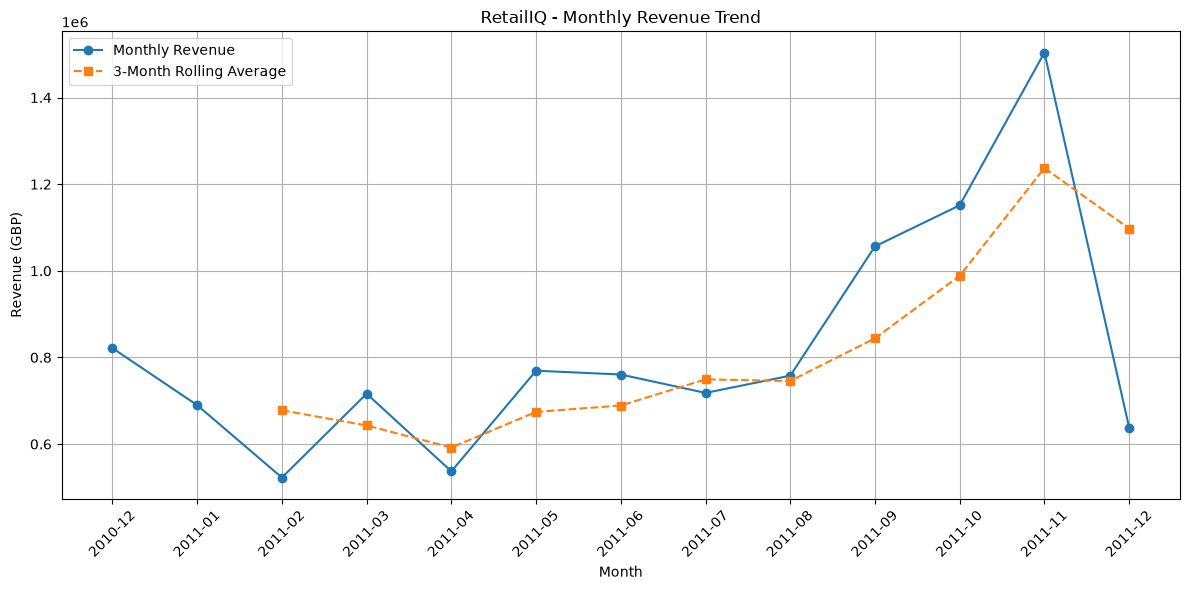

In [140]:
plt.figure(figsize=(12,6))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o',
    label='Monthly Revenue'
)
plt.plot(
    rolling_3m.index.astype(str),
    rolling_3m.values,
    marker='s',
    linestyle='--',
    label='3-Month Rolling Average'
)
plt.title('RetailIQ - Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (GBP)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\04_Pandas\\RetailIQ\\outputs\\charts\\monthly_revenue_trend.png",dpi=300)
plt.show()

In [141]:
customer_sales=sales.dropna(subset=['CustomerID']).copy()
customer_summary=customer_sales.groupby('CustomerID').agg(
    Last_Purchase=('InvoiceDate','max'),
    Frequency=('InvoiceNo','nunique'),
    Monetary=('Revenue','sum')
)
display(customer_summary.head(10))

,Last_Purchase,Frequency,Monetary
CustomerID,,,
12346.0,2011-01-18 10:01:00,1,77183.60
12347.0,2011-12-07 15:52:00,7,4310.00
12348.0,2011-09-25 13:13:00,4,1797.24
12349.0,2011-11-21 09:51:00,1,1757.55
12350.0,2011-02-02 16:01:00,1,334.40
12352.0,2011-11-03 14:37:00,8,2506.04
12353.0,2011-05-19 17:47:00,1,89.00
12354.0,2011-04-21 13:11:00,1,1079.40
12355.0,2011-05-09 13:49:00,1,459.40


In [142]:
print(customer_sales['CustomerID'].head(10))
print(customer_sales['CustomerID'].nunique())
print(customer_summary.shape)
print(customer_summary.isnull().sum())

0    17850.0
1    17850.0
2    17850.0
3    17850.0
4    17850.0
5    17850.0
6    17850.0
7    17850.0
8    17850.0
9    13047.0
Name: CustomerID, dtype: float64
4339
(4339, 3)
Last_Purchase    0
Frequency        0
Monetary         0
dtype: int64


In [143]:
snapshot_date=sales['InvoiceDate'].max()+pd.Timedelta(days=1)
print("Analysis date : ",snapshot_date)

Analysis date :  2011-12-10 12:50:00


In [144]:
customer_summary['Recency']=(snapshot_date-customer_summary['Last_Purchase']).dt.days
display(customer_summary.head(10))

,Last_Purchase,Frequency,Monetary,Recency
CustomerID,,,,
12346.0,2011-01-18 10:01:00,1,77183.60,326
12347.0,2011-12-07 15:52:00,7,4310.00,2
12348.0,2011-09-25 13:13:00,4,1797.24,75
12349.0,2011-11-21 09:51:00,1,1757.55,19
12350.0,2011-02-02 16:01:00,1,334.40,310
12352.0,2011-11-03 14:37:00,8,2506.04,36
12353.0,2011-05-19 17:47:00,1,89.00,204
12354.0,2011-04-21 13:11:00,1,1079.40,232
12355.0,2011-05-09 13:49:00,1,459.40,214


In [145]:
customer_summary['R_Score']=pd.qcut(
    customer_summary['Recency'].rank(method='first'),
    4, labels=[4,3,2,1]
)
customer_summary['F_Score']=pd.qcut(
    customer_summary["Frequency"].rank(method='first'),
    4, labels=[1,2,3,4]
)
customer_summary['M_Score']=pd.qcut(
    customer_summary['Monetary'].rank(method='first'),
    4, labels=[1,2,3,4]
)
display(customer_summary.head(10))

,Last_Purchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score
CustomerID,,,,,,,
12346.0,2011-01-18 10:01:00,1,77183.60,326,1,1,4
12347.0,2011-12-07 15:52:00,7,4310.00,2,4,4,4
12348.0,2011-09-25 13:13:00,4,1797.24,75,2,3,4
12349.0,2011-11-21 09:51:00,1,1757.55,19,3,1,4
12350.0,2011-02-02 16:01:00,1,334.40,310,1,1,2
12352.0,2011-11-03 14:37:00,8,2506.04,36,3,4,4
12353.0,2011-05-19 17:47:00,1,89.00,204,1,1,1
12354.0,2011-04-21 13:11:00,1,1079.40,232,1,1,3
12355.0,2011-05-09 13:49:00,1,459.40,214,1,1,2


In [146]:
customer_summary['RFM_Score']=(
    customer_summary['R_Score'].astype(str) +
    customer_summary['F_Score'].astype(str) +
    customer_summary['M_Score'].astype(str) 
)
customer_summary['RFM_Total']=(    
    customer_summary['R_Score'].astype(int) +
    customer_summary['F_Score'].astype(int) +
    customer_summary['M_Score'].astype(int)
)
display(customer_summary.head(10))

,Last_Purchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
CustomerID,,,,,,,,,
12346.0,2011-01-18 10:01:00,1,77183.60,326,1,1,4,114,6
12347.0,2011-12-07 15:52:00,7,4310.00,2,4,4,4,444,12
12348.0,2011-09-25 13:13:00,4,1797.24,75,2,3,4,234,9
12349.0,2011-11-21 09:51:00,1,1757.55,19,3,1,4,314,8
12350.0,2011-02-02 16:01:00,1,334.40,310,1,1,2,112,4
12352.0,2011-11-03 14:37:00,8,2506.04,36,3,4,4,344,11
12353.0,2011-05-19 17:47:00,1,89.00,204,1,1,1,111,3
12354.0,2011-04-21 13:11:00,1,1079.40,232,1,1,3,113,5
12355.0,2011-05-09 13:49:00,1,459.40,214,1,1,2,112,4


In [147]:
customer_summary['RFM_Score']=pd.to_numeric(
    customer_summary['RFM_Total']
 #   errors='coerce'
)
print(customer_summary['RFM_Total'].dtype)
print(customer_summary['RFM_Total'].isnull().sum())

int64
0


In [148]:
def segment_customer(row):
    if row["RFM_Total"]>=10:
        return 'Champions'
    elif row["RFM_Total"]>=8:
        return 'Loyal Customers'
    elif row["RFM_Total"]>=6:
        return 'Potential Loyalists'
    elif row["RFM_Total"]>=4:
        return 'At Risk'
    else:
        return 'Lost Customers'


In [149]:
customer_summary['Customer_Segment']=customer_summary.apply(
    segment_customer, axis=1
)

print(customer_summary['Customer_Segment'].value_counts())

Customer_Segment
Champions              1260
At Risk                 994
Potential Loyalists     941
Loyal Customers         844
Lost Customers          300
Name: count, dtype: int64


In [150]:
segment_analysis=customer_summary.groupby('Customer_Segment').agg(
    Customer_Count=('Customer_Segment','count'),
    Total_Revenue=('Monetary','sum'),
    Average_Revenue=('Monetary','mean')
)
print(segment_analysis.round(2))

                     Customer_Count  Total_Revenue  Average_Revenue
Customer_Segment                                                   
At Risk                         994      310448.20           312.32
Champions                      1260     6819332.77          5412.17
Lost Customers                  300       48358.23           161.19
Loyal Customers                 844     1054826.08          1249.79
Potential Loyalists             941      654243.61           695.26


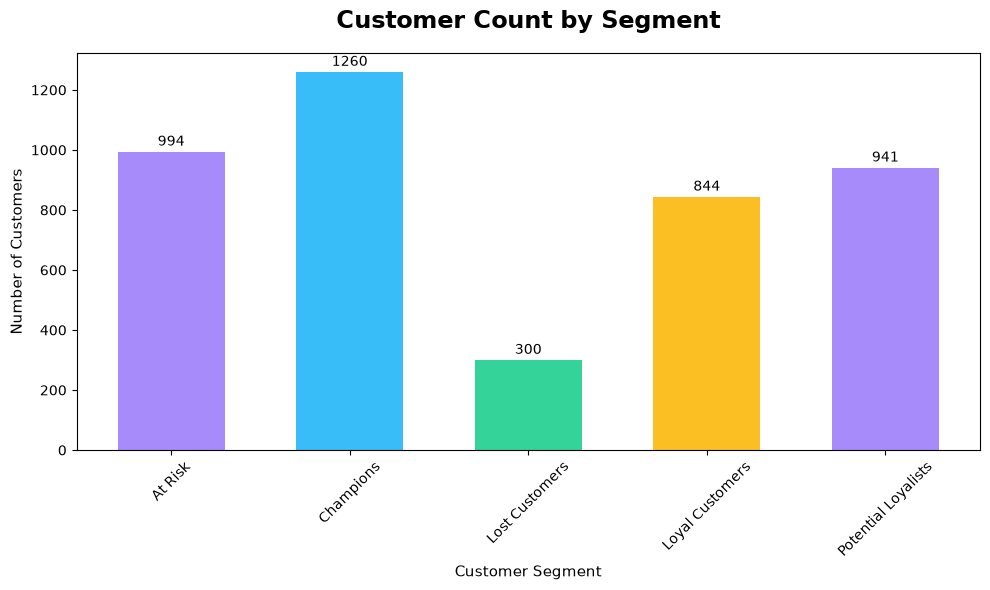

In [151]:
plt.figure(figsize=(10,6))
segment_analysis.sort_values("Customer_Count")
plt.bar(
    segment_analysis.index,
    segment_analysis['Customer_Count'],
    width=0.6,
    color=['#A78BFA','#38BDF8','#34D399','#FBBF24']
    )
for container in plt.gca().containers:
    plt.bar_label(container,fmt='%.0f',padding=2)
plt.title("Customer Count by Segment",fontsize=17,fontweight='bold',pad=18)
plt.xlabel("Customer Segment",fontsize=11)
plt.ylabel('Number of Customers',fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\04_Pandas\\RetailIQ\\outputs\\charts\\customer_count_by_segment.png",dpi=300,bbox_inches='tight')
plt.show()

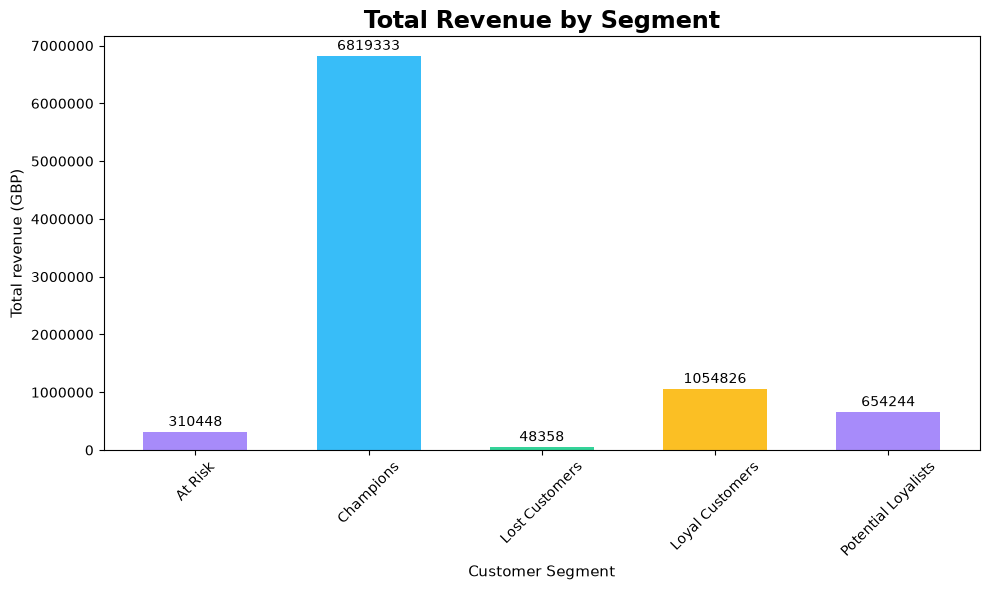

In [152]:
plt.figure(figsize=(10,6))
segment_analysis.sort_values('Total_Revenue')
plt.bar(
    segment_analysis.index,
    segment_analysis['Total_Revenue'],
    width=0.6,
    color=['#A78BFA','#38BDF8','#34D399','#FBBF24']
    )
for container in plt.gca().containers:
    plt.bar_label(container,fmt='%.0f',padding=2)
plt.title("Total Revenue by Segment",fontsize=17,fontweight='bold')
plt.xlabel("Customer Segment",fontsize=11)
plt.ylabel('Total revenue (GBP)',fontsize=11)
plt.xticks(rotation=45)
plt.ticklabel_format(axis='y',style='plain')
plt.tight_layout()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\04_Pandas\\RetailIQ\\outputs\\charts\\revenue_by_customer_segment.png",dpi=300,bbox_inches='tight')
plt.show()

In [153]:
product_analysis=(
    sales.dropna(subset=['Description']).groupby(['StockCode','Description']).agg(
        Total_Quality=('Quantity','sum'),
        Total_Revenue=('Revenue','sum'),
        Total_Orders=('InvoiceNo','nunique')
        ).sort_values('Total_Revenue',ascending=False)
)
display(product_analysis.head(10))

,,Total_Quality,Total_Revenue,Total_Orders
StockCode,Description,,,
DOT,DOTCOM POSTAGE,708,206248.77,708
22423,REGENCY CAKESTAND 3 TIER,13862,174156.54,1989
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24,2193
47566,PARTY BUNTING,18287,99445.23,1686
85099B,JUMBO BAG RED RETROSPOT,48375,94159.81,2092
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
POST,POSTAGE,3150,78101.88,1126
M,Manual,6990,77750.27,294


In [154]:
sales[sales['StockCode']=='23843'][['InvoiceNo','Description','Quantity','UnitPrice','Revenue']].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,Revenue


In [155]:
print(sales.columns.tolist())
sales.columns=sales.columns.str.strip()

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'TransactionType', 'Year', 'Month', 'YearMonth']


In [156]:
sales[sales['StockCode'].isin(['DOT','POST','M'])][['StockCode', 'Description']].drop_duplicates()

,StockCode,Description
45,POST,POSTAGE
1814,DOT,DOTCOM POSTAGE
2239,M,Manual


In [157]:
product_sales=sales[
    -sales['StockCode'].isin(['POST','DOT','M'])
].copy()

In [158]:
print(product_sales['StockCode'].isin(['POST','DOT','M']).sum())

0


In [159]:
product_analysis=(
    product_sales.dropna(subset=['Description'])
    .groupby(['StockCode','Description'])
    .agg(
        Total_Quantity=('Quantity','sum'),
        Total_Revenue=('Revenue','sum'),
        Total_Orders=('InvoiceNo','nunique')
        )
    .sort_values('Total_Revenue',ascending=False)
)
display(product_analysis.head(10))

,,Total_Quantity,Total_Revenue,Total_Orders
StockCode,Description,,,
22423,REGENCY CAKESTAND 3 TIER,13862,174156.54,1989
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584,104284.24,2193
47566,PARTY BUNTING,18287,99445.23,1686
85099B,JUMBO BAG RED RETROSPOT,48375,94159.81,2092
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
23084,RABBIT NIGHT LIGHT,30739,66870.03,994
22086,PAPER CHAIN KIT 50'S CHRISTMAS,19329,64875.59,1160
84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455


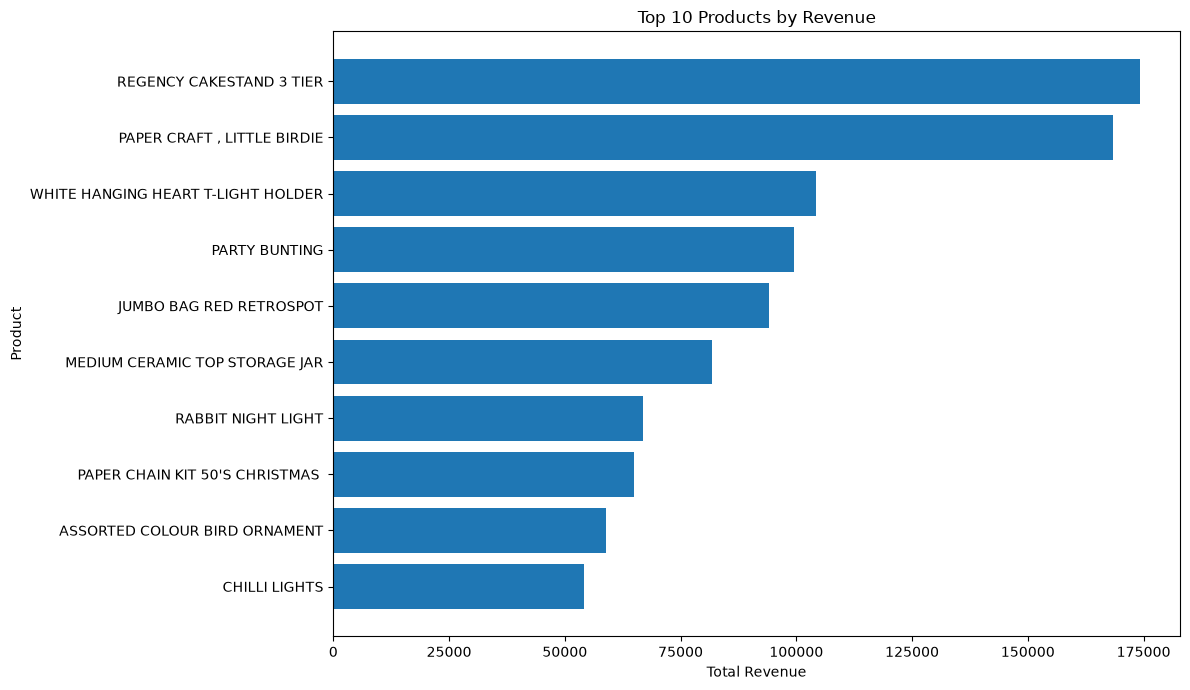

In [160]:
top_products=product_analysis.head(10).sort_values(
    'Total_Revenue'
)
plt.figure(figsize=(12,7))
plt.barh(
    top_products.index.get_level_values('Description'),
    top_products['Total_Revenue']
)
plt.title("Top 10 Products by Revenue")
plt.xlabel('Total Revenue')
plt.ylabel('Product')
plt.ticklabel_format(axis='x',style='plain')
plt.tight_layout()
plt.savefig('C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\04_Pandas\\RetailIQ\\outputs\\charts\\top_10_products_by_revenue.png',dpi=300,bbox_inches='tight')
plt.show()

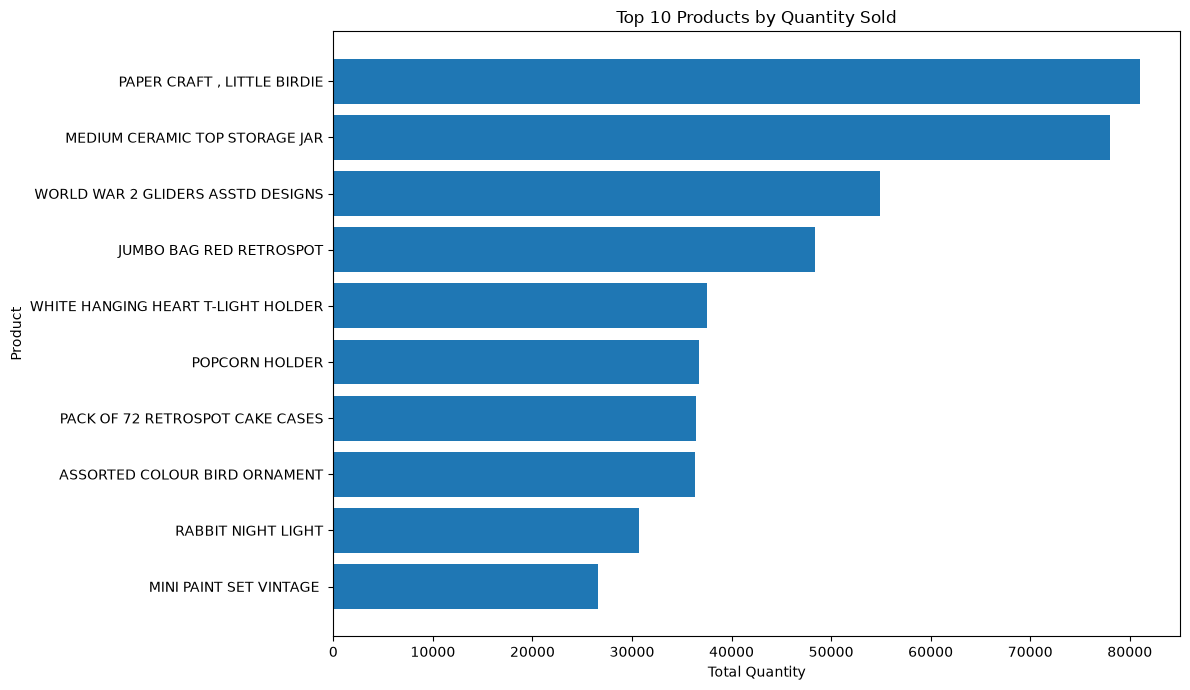

In [161]:
top_quantity=product_analysis.nlargest(10,'Total_Quantity').sort_values(
    'Total_Quantity'
)
plt.figure(figsize=(12,7))
plt.barh(
    top_quantity.index.get_level_values('Description'),
    top_quantity['Total_Quantity']
)
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel('Total Quantity')
plt.ylabel('Product')
plt.tight_layout()
plt.savefig('C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\04_Pandas\\RetailIQ\\outputs\\charts\\top_10_products_by_quantity.png',dpi=300,bbox_inches='tight')
plt.show()

In [164]:
print('Total Products : ',product_analysis.shape[0])
print('Highest Revenue Product : ')
print(product_analysis['Total_Revenue'].idxmax())
print('Highest Quantity Product : ')
print(product_analysis['Total_Quantity'].idxmax())
print("Average Product Revenue : ",round(product_analysis['Total_Revenue'].mean(),2))


Total Products :  4316
Highest Revenue Product : 
(22423, 'REGENCY CAKESTAND 3 TIER')
Highest Quantity Product : 
(23843, 'PAPER CRAFT , LITTLE BIRDIE')
Average Product Revenue :  2381.84
